# Silverbox Benchmark

This notebook trains a **linear time-invariant (LTI)** state-space model,
**Affine LPV-LFR** models and **Nonlinear-LFR (NLLFR)** models on the Silverbox benchmark,
which is available through the `nonlinear_benchmarks` dataloader.

In [1]:
# Initialize JAX settings
import os

os.environ["JAX_PLATFORMS"] = "cpu"  # or "cuda"
import jax

jax.config.update("jax_enable_x64", True)  # enforce float64 usage
jax.config.update("jax_num_cpu_devices", 16)  # number of CPU threads

# Optional, machine-specific: pin the process to the performance cores.
PIN_TO_P_CORES = True
if PIN_TO_P_CORES:
    import psutil

    psutil.Process(os.getpid()).cpu_affinity(list(range(16)))

import jax.numpy as jnp
import nonlinear_benchmarks
import identax as idx
from matplotlib import pyplot as plt

## 1. Load the Silverbox data

In [2]:
train_val, test_sets = nonlinear_benchmarks.Silverbox(atleast_2d=True)

# The single multisine record is split into a training and a validation segment.
N_train = int(0.8 * len(train_val.u))
data_train = idx.iddata(jnp.asarray(train_val.u[:N_train]), jnp.asarray(train_val.y[:N_train]))
data_val = idx.iddata(jnp.asarray(train_val.u[N_train:]), jnp.asarray(train_val.y[N_train:]))

# Three test records are available; we use each of them for evaluation.
test_data = [idx.iddata(jnp.asarray(t.u), jnp.asarray(t.y)) for t in test_sets]

print(f"Shape of training data:   U={data_train.U.shape}, Y={data_train.Y.shape}")
print(f"Shape of validation data: U={data_val.U.shape}, Y={data_val.Y.shape}")
for i, d in enumerate(test_data):
    print(f"Shape of test[{i}] data:    U={d.U.shape}, Y={d.Y.shape}")

Shape of training data:   U=(52049, 1), Y=(52049, 1)
Shape of validation data: U=(13013, 1), Y=(13013, 1)
Shape of test[0] data:    U=(21688, 1), Y=(21688, 1)
Shape of test[1] data:    U=(40475, 1), Y=(40475, 1)
Shape of test[2] data:    U=(32000, 1), Y=(32000, 1)


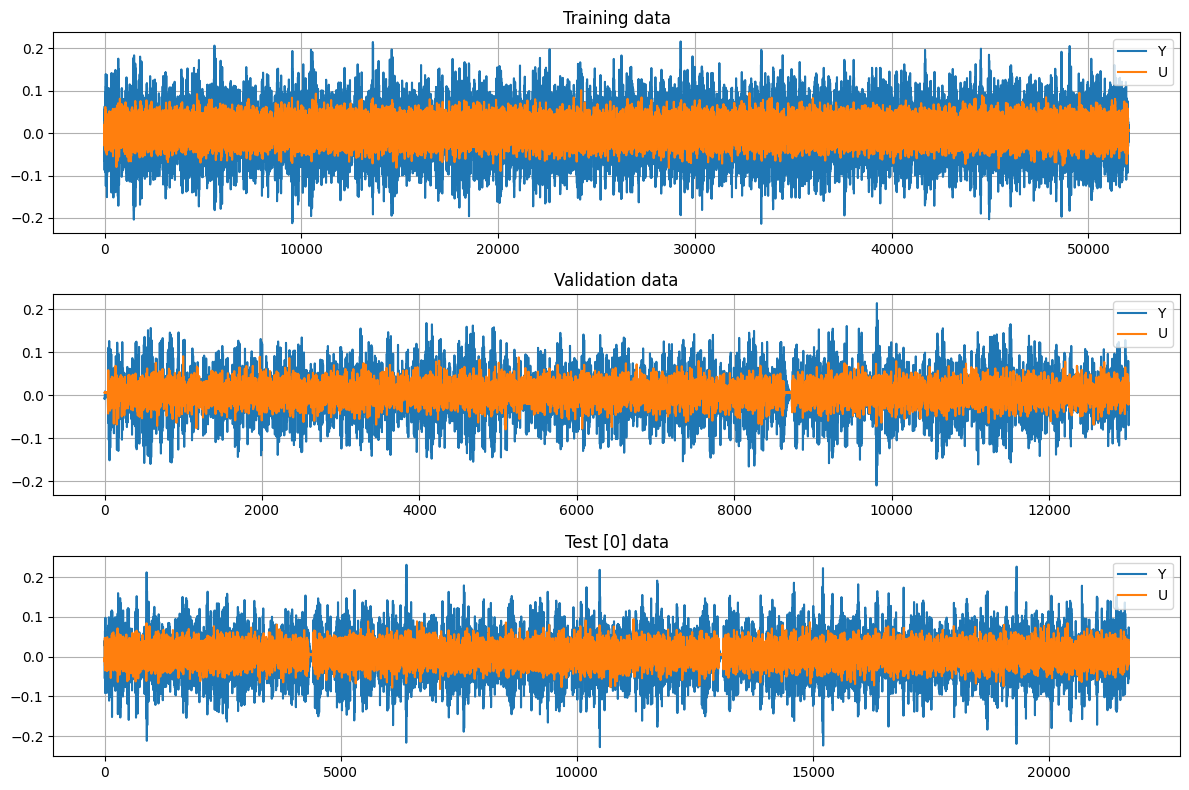

In [3]:
plot_sets = {"Training": data_train, "Validation": data_val, "Test [0]": test_data[0]}

fig, axs = plt.subplots(len(plot_sets), 1, figsize=(12, 8))
for ax, (title, d) in zip(axs, plot_sets.items()):
    ax.plot(d.Y, label="Y")
    ax.plot(d.U, label="U")
    ax.set_title(f"{title} data")
    ax.legend(loc="upper right")
    ax.grid()

plt.tight_layout()
plt.show()

## 2. Train an LTI state-space model

The LTI model serves as a baseline and as a warm start for the LPV and NLLFR models below.

In [4]:
nu = 1
ny = 1
nx = 2

key = jax.random.PRNGKey(42)  # same key for all models, for reproducibility

lti_cfg = idx.LinStateSpaceConfig(nx=nx, nu=nu, ny=ny)
lti_mod = idx.ModelLinStateSpace(lti_cfg, key)

optim_cfg_lti = idx.OptimConfig(adam_epochs=1000, lbfgs_epochs=1000)

In [5]:
x0_init = jnp.zeros((nx,))
lti_mod, x0_train_lti, lti_history = idx.optimize(
    sys=lti_mod,
    train_data=data_train,
    x0=x0_init,
    config=optim_cfg_lti,
    val_data=data_val,
)

DataScaler not yet initialized, initializing using training data.


LTI validation RMSE (x 1000): 5.792


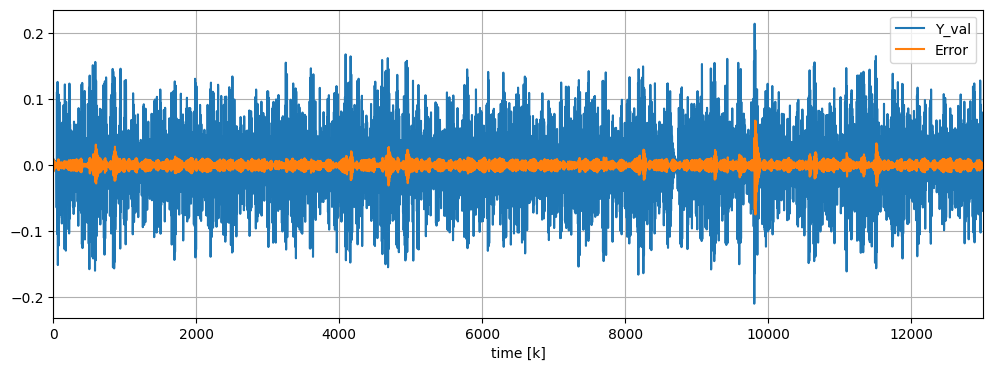

In [6]:
Yhat_val_lti, _ = lti_mod.simulate(data_val, x0_init)
RMSE_val_lti = idx.metrics.RMSE(data_val.Y, Yhat_val_lti)
print(f"LTI validation RMSE (x 1000): {1000 * RMSE_val_lti[0]:.3f}")

plt.figure(figsize=(12, 4))
plt.plot(data_val.Y, label="Y_val")
plt.plot(data_val.Y - Yhat_val_lti, label="Error")
plt.xlabel("time [k]")
plt.autoscale(axis="x", tight=True)
plt.legend()
plt.grid()
plt.show()

## 3. Initialize and train Affine LPV-LFR models

The linear part of the LPV-LFR model is warm-started from the LTI model, after normalizing its
states using the simulated state trajectory on the training data. Two models are trained:
one with single shooting (simulation over the full training record) and one with
unconstrained multiple shooting (UMS), which splits the record into short sub-records.

In [7]:
# State normalization using the simulated state trajectory on the training data.
_, Xhat_train_lti = lti_mod.simulate(data_train, x0_init)
lti_scaled = idx.scale_lti_ss(lti_mod.A, lti_mod.B_u, lti_mod.C_y, lti_mod.D_yu, Xhat_train_lti)

# Configuration of the scheduling map
sched_cfg = idx.SchedulingMapConfig(layers=2, neurons_per_layer=6)

# Configuration of the LPV-LFR model
lpv_cfg = idx.AffineLPVLFRConfig(
    nx=nx,
    nu=nu,
    ny=ny,
    npar=1,                   # number of scheduling variables
    nreps=2,                  # number of repetitions per scheduling variable
    nd=0,                     # no exogenous scheduling signals
    SchedulingMap=sched_cfg,
    StateEncoder=None,        # no state encoder is trained
    scalers="standard",
)

# Optimizer settings shared by the single-shooting LPV and NLLFR models
optim_cfg_ss = idx.OptimConfig(
    adam_epochs=1000,
    lbfgs_epochs=20000,
    shooting_type="single",
    l2_rho=1e-6,     # add some L2 regularization
    grad_tol=1e-10,  # smaller tolerance than the default
)

# Optimizer settings shared by the UMS LPV and NLLFR models
optim_cfg_ums = idx.OptimConfig(
    adam_epochs=1000,
    lbfgs_epochs=20000,
    shooting_type="multiple",  # use unconstrained multiple shooting
    T=200,                     # sub-record length of 200 samples
    l2_rho=1e-6,               # add some L2 regularization
    lbfgs_max_ls=20,
    grad_tol=1e-10,            # smaller tolerance than the default
)

### Single shooting

In [8]:
aff_mod = idx.ModelAffineLPVLFR(lpv_cfg, key, init_sys=lti_scaled)

aff_mod, x0_train_aff, aff_history = idx.optimize(
    aff_mod,
    data_train,
    x0_init,
    optim_cfg_ss,
    val_data=data_val,
)

DataScaler not yet initialized, initializing using training data.


### Unconstrained multiple shooting

In [9]:
aff_mod_ums = idx.ModelAffineLPVLFR(lpv_cfg, key, init_sys=lti_scaled)

aff_mod_ums, x0_train_aff_ums, aff_history_ums = idx.optimize(
    aff_mod_ums,
    data_train,
    x0_init,
    optim_cfg_ums,
    val_data=data_val,
)

DataScaler not yet initialized, initializing using training data.


## 4. Initialize and train Nonlinear-LFR models

The NLLFR models use the same warm start and the same optimizer settings as the LPV models.
After initialization, the latent signals are rescaled to the training data.

In [10]:
nllfr_cfg = idx.NLLFRConfig(
    nx=nx,
    nu=nu,
    ny=ny,
    nw=1,
    nz=1,
    DeltaMap=idx.NetworkConfig(neurons_per_layer=6, clip=False),
    StateEncoder=None,
    scalers="standard",
)

### Single shooting

In [11]:
nllfr_mod = idx.ModelNLLFR(nllfr_cfg, key, init_sys=lti_scaled)
nllfr_mod = nllfr_mod.rescale(data_train)  # scale latent signals to training data

nllfr_mod, x0_train_nllfr, nllfr_history = idx.optimize(
    nllfr_mod,
    data_train,
    x0_init,
    optim_cfg_ss,
    val_data=data_val,
)

### Unconstrained multiple shooting

In [12]:
nllfr_mod_ums = idx.ModelNLLFR(nllfr_cfg, key, init_sys=lti_scaled)
nllfr_mod_ums = nllfr_mod_ums.rescale(data_train)  # scale latent signals to training data

nllfr_mod_ums, x0_train_nllfr_ums, nllfr_history_ums = idx.optimize(
    nllfr_mod_ums,
    data_train,
    x0_init,
    optim_cfg_ums,
    val_data=data_val,
)

## 5. Evaluate the models

For each dataset the initial state is estimated from the first `N_TRANSIENT` samples,
which are then excluded from the RMSE.

In [13]:
N_TRANSIENT = 50

datasets = {"train": data_train, "val": data_val}
for i, d in enumerate(test_data):
    datasets[f"test[{i}]"] = d

# model name -> (trained model, training history)
trained = {
    "LTI": (lti_mod, lti_history),
    "Affine LPV-LFR": (aff_mod, aff_history),
    "Affine LPV-LFR (UMS)": (aff_mod_ums, aff_history_ums),
    "NLLFR": (nllfr_mod, nllfr_history),
    "NLLFR (UMS)": (nllfr_mod_ums, nllfr_history_ums),
}

results = {}
for model_name, (model, _) in trained.items():
    results[model_name] = {}
    for name, d in datasets.items():
        x0, _ = idx.learn_initial_state(model, d, x0_init, lbfgs_epochs=100, T=N_TRANSIENT)
        Yhat, _ = model.simulate(d, x0)
        rmse = idx.metrics.RMSE(d.Y[N_TRANSIENT:], Yhat[N_TRANSIENT:])
        results[model_name][name] = (Yhat, rmse)

# Print the RMSE (x 1000) per model and dataset, and the training time.
print(f"{'RMSE x 1000':22s}" + "".join(f"{name:>10s}" for name in datasets) + f"{'time [s]':>10s}")
for model_name, model_results in results.items():
    rmses = "".join(f"{1000 * model_results[name][1][0]:10.3f}" for name in datasets)
    print(f"{model_name:22s}{rmses}{trained[model_name][1].total_time:10.1f}")

RMSE x 1000                train       val   test[0]   test[1]   test[2]  time [s]
LTI                        6.898     5.797     6.956    14.363     6.582       2.5
Affine LPV-LFR             0.208     0.209     0.215     0.376     0.225     177.6
Affine LPV-LFR (UMS)       0.216     0.218     0.222     0.289     0.240     172.4
NLLFR                      0.240     0.240     0.248     0.421     0.258     153.0
NLLFR (UMS)                0.242     0.243     0.250     0.538     0.263     132.3


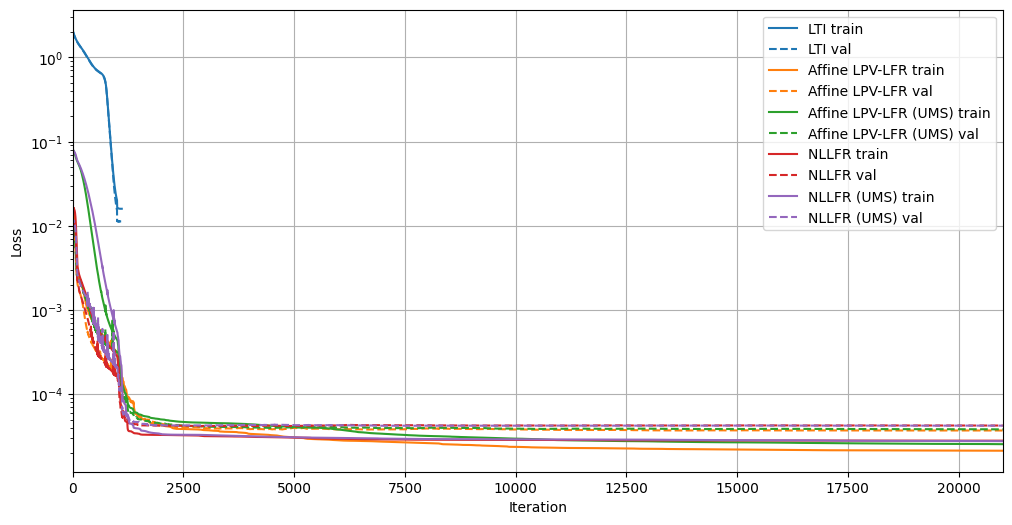

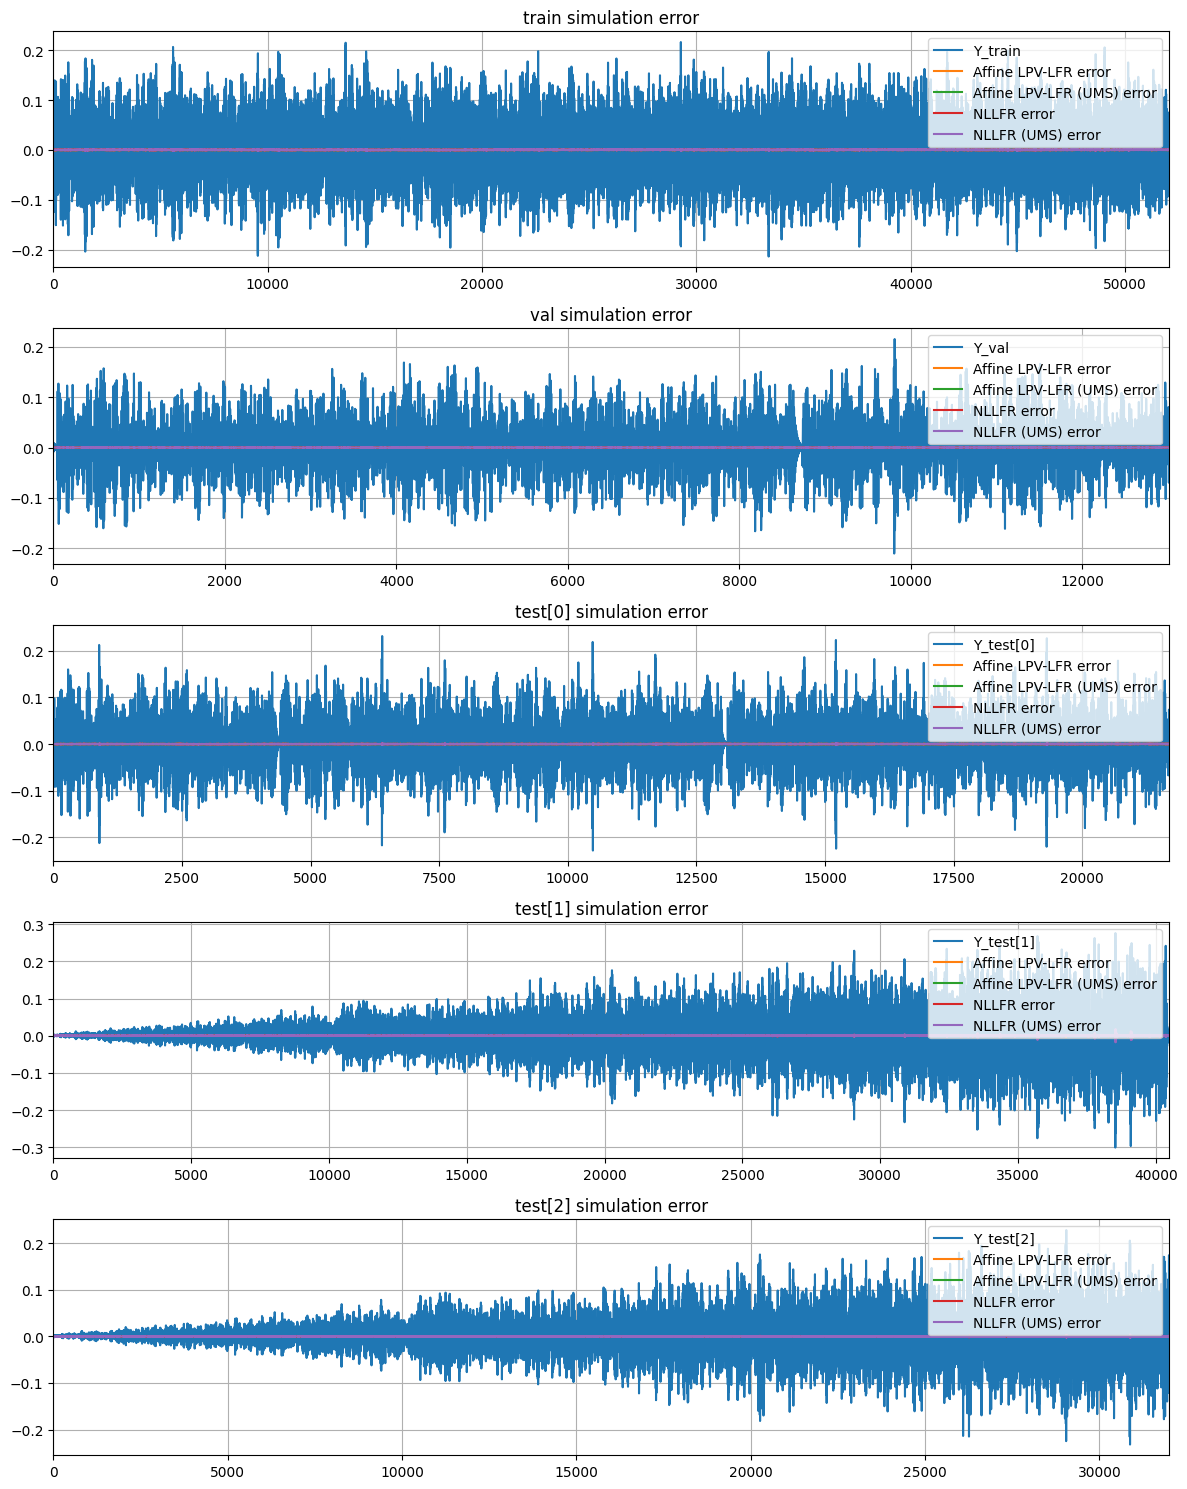

In [14]:
# Training (solid) and validation (dashed) loss of all models.
fig = plt.figure(figsize=(12, 6))
for model_name, (_, history) in trained.items():
    line, = plt.semilogy(history.train, label=f"{model_name} train")
    plt.semilogy(history.val, linestyle="--", color=line.get_color(), label=f"{model_name} val")
plt.autoscale(axis="x", tight=True)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.grid()
fig.savefig("silverbox_training_loss.pdf", bbox_inches="tight")
plt.show()

# LTI is left out of the error plots: its error is expected to dwarf the others.
fig, axs = plt.subplots(len(datasets), 1, figsize=(12, 3 * len(datasets)))
for ax, (name, d) in zip(axs, datasets.items()):
    ax.plot(d.Y, label=f"Y_{name}")
    for model_name, model_results in results.items():
        if model_name == "LTI":
            continue
        ax.plot(d.Y - model_results[name][0], label=f"{model_name} error")
    ax.set_title(f"{name} simulation error")
    ax.autoscale(axis="x", tight=True)
    ax.legend(loc="upper right")
    ax.grid()

plt.tight_layout()
fig.savefig("silverbox_simulation_error.pdf", bbox_inches="tight")
plt.show()